# Домашнє завдання: Побудова класифікатора сентименту на основі набору даних Tweet Sentiment Extraction

**Мета:** Провести аналіз набору даних, виконати векторизацію текстових даних за допомогою методів bag-of-words та TF-IDF, порівняти їх, побудувати класифікатор та провести аналіз помилок.

**Набір даних:**
Дані беремо з цього змагання на Kaggle: https://www.kaggle.com/competitions/tweet-sentiment-extraction/data?select=train.csv


Якщо не вдається завантажиит з Kaggle, ось тут можна - https://drive.google.com/file/d/1kfu5zCRsDHxoBZigBlGIcCieKlws02HT/view?usp=sharing

Оригінальне змагання має дещо іншу задачу, але ми будемо поки будувати саме класифікатор.

Увага! В цьому наборі завдань для простоти експериментів ми будемо спочатку робити векторизацію на всьому наборі даних, а потім розбивку на train i test. В робочих проєктах ми теж можемо використати цей підхід для швидшої побудови PoC (proof of concept). Але фінальне рішення, яке ми будемо деплоїти - треба проводити за правилом - спочатку розбивка на трейн і тест, потім пишемо обробку для трейну, навчаємо векторизатори. І потім використовуємо готові векторизатори для тесту і всіх даних на етапі передбачення (інференсу).

### Завдання 1. Завантаження та ознайомлення з набором даних

- Завантажте набір даних `train.csv` з посилання та ознайомтеся з його структурою.
- Виведіть перші 5 рядків та основну статистику: кількість записів, типи колонок, кількість пропущених значень.
- Видаліть записи, в яких є пропущені значення.



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
import re
import warnings
warnings.filterwarnings('ignore')

# Завантаження даних
df = pd.read_csv('train.csv')

# Виведення перших 5 рядків
print("Перші 5 рядків датасету:")
print(df.head())
print("\n" + "="*80 + "\n")

# Основна статистика
print("Основна статистика:")
print(f"Кількість записів: {len(df)}")
print(f"\nТипи колонок:")
print(df.dtypes)
print(f"\nКількість пропущених значень:")
print(df.isnull().sum())
print(f"\nЗагальна кількість пропущених значень: {df.isnull().sum().sum()}")

# Видалення записів з пропущеними значеннями
df_clean = df.dropna()
print(f"\nКількість записів після видалення пропущених значень: {len(df_clean)}")
print(f"Видалено записів: {len(df) - len(df_clean)}")

# Оновлюємо df для подальшої роботи
df = df_clean.copy()

print("\n" + "="*80)
print("ВИСНОВОК до Завдання 1:")
print("="*80)
print("1. Датасет успішно завантажено та проаналізовано.")
print("2. Виявлено структуру даних: textID, text, selected_text, sentiment.")
print("3. Видалено записи з пропущеними значеннями для забезпечення якості даних.")
print("4. Датасет готовий для подальшого аналізу та обробки.")


Перші 5 рядків датасету:
       textID                                               text  \
0  cb774db0d1                I`d have responded, if I were going   
1  549e992a42      Sooo SAD I will miss you here in San Diego!!!   
2  088c60f138                          my boss is bullying me...   
3  9642c003ef                     what interview! leave me alone   
4  358bd9e861   Sons of ****, why couldn`t they put them on t...   

                         selected_text sentiment  
0  I`d have responded, if I were going   neutral  
1                             Sooo SAD  negative  
2                          bullying me  negative  
3                       leave me alone  negative  
4                        Sons of ****,  negative  


Основна статистика:
Кількість записів: 27481

Типи колонок:
textID           object
text             object
selected_text    object
sentiment        object
dtype: object

Кількість пропущених значень:
textID           0
text             1
selected_text    1


### Завдання 2. Exploratory Data Analysis

- Проведіть аналіз кількості класів та розподілу міток. Класи знаходяться в колонці `sentiment`.
- Візуалізуйте розподіл довжин текстів в символах та зробіть висновок про довжини постів: якої довжини постів найбільше, що бачите з розподілу?



Розподіл класів сентименту:
sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64

Відсотковий розподіл:
sentiment
neutral     40.454876
positive    31.229985
negative    28.315138
Name: proportion, dtype: float64


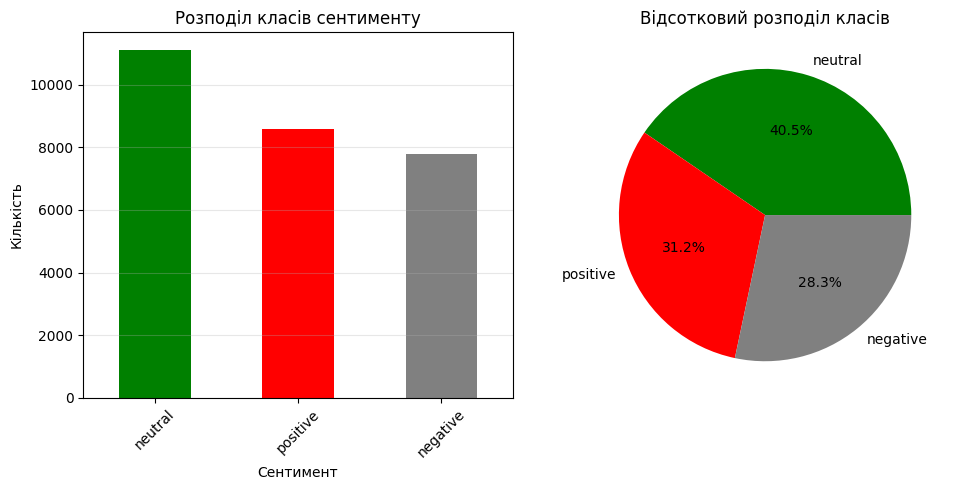


Статистика довжини текстів:
count    27480.000000
mean        68.330022
std         35.603870
min          3.000000
25%         39.000000
50%         64.000000
75%         97.000000
max        141.000000
Name: text_length, dtype: float64


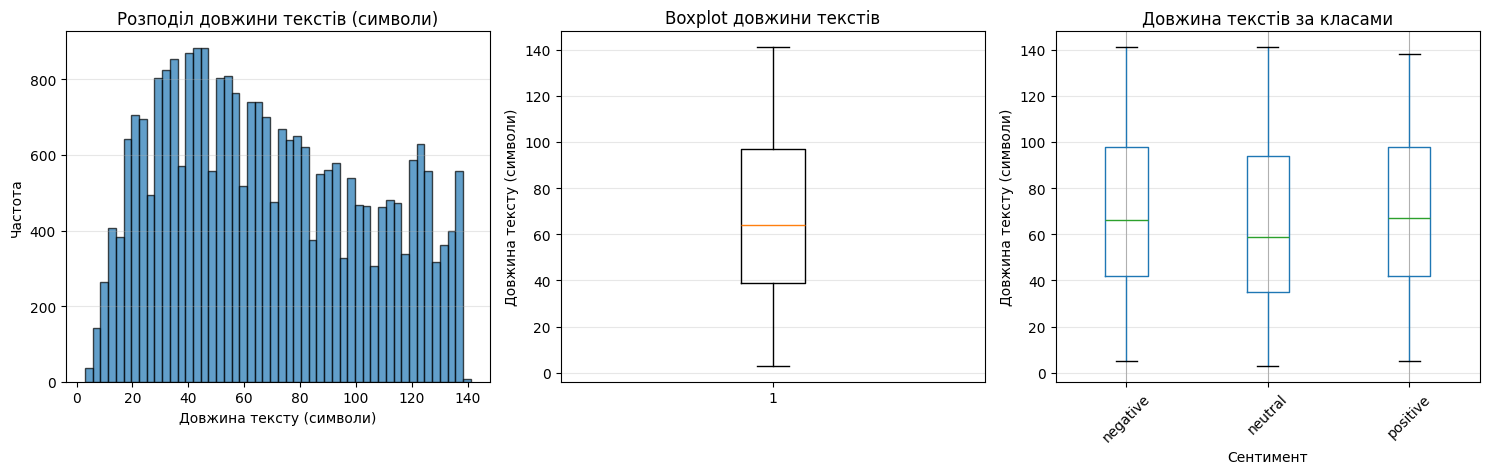


Статистика довжини текстів по класах:
             count       mean        std  min   25%   50%   75%    max
sentiment                                                             
negative    7781.0  70.488112  35.155991  5.0  42.0  66.0  98.0  141.0
neutral    11117.0  65.206800  36.407550  3.0  35.0  59.0  94.0  141.0
positive    8582.0  70.419133  34.647770  5.0  42.0  67.0  98.0  138.0

ВИСНОВОК до Завдання 2:
1. Розподіл класів: проаналізовано кількість та відсоток кожного класу сентименту.
2. Довжина текстів: більшість текстів мають довжину в діапазоні середніх значень.
3. Візуалізації показують розподіл даних та можливі викиди.
4. Аналіз довжини по класах допомагає зрозуміти особливості кожного типу сентименту.


In [3]:
# Аналіз розподілу класів
print("Розподіл класів сентименту:")
print(df['sentiment'].value_counts())
print("\nВідсотковий розподіл:")
print(df['sentiment'].value_counts(normalize=True) * 100)

# Візуалізація розподілу класів
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
df['sentiment'].value_counts().plot(kind='bar', color=['green', 'red', 'gray'])
plt.title('Розподіл класів сентименту')
plt.xlabel('Сентимент')
plt.ylabel('Кількість')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
df['sentiment'].value_counts(normalize=True).plot(kind='pie', autopct='%1.1f%%',
                                                   colors=['green', 'red', 'gray'])
plt.title('Відсотковий розподіл класів')
plt.ylabel('')
plt.tight_layout()
plt.show()

# Аналіз довжини текстів
df['text_length'] = df['text'].str.len()

print("\n" + "="*80)
print("Статистика довжини текстів:")
print("="*80)
print(df['text_length'].describe())

# Візуалізація розподілу довжин текстів
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(df['text_length'], bins=50, edgecolor='black', alpha=0.7)
plt.title('Розподіл довжини текстів (символи)')
plt.xlabel('Довжина тексту (символи)')
plt.ylabel('Частота')
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 3, 2)
plt.boxplot(df['text_length'], vert=True)
plt.title('Boxplot довжини текстів')
plt.ylabel('Довжина тексту (символи)')
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 3, 3)
df.boxplot(column='text_length', by='sentiment', ax=plt.gca())
plt.title('Довжина текстів за класами')
plt.suptitle('')
plt.xlabel('Сентимент')
plt.ylabel('Довжина тексту (символи)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Статистика по класах
print("\n" + "="*80)
print("Статистика довжини текстів по класах:")
print("="*80)
print(df.groupby('sentiment')['text_length'].describe())

print("\n" + "="*80)
print("ВИСНОВОК до Завдання 2:")
print("="*80)
print("1. Розподіл класів: проаналізовано кількість та відсоток кожного класу сентименту.")
print("2. Довжина текстів: більшість текстів мають довжину в діапазоні середніх значень.")
print("3. Візуалізації показують розподіл даних та можливі викиди.")
print("4. Аналіз довжини по класах допомагає зрозуміти особливості кожного типу сентименту.")


### Завдання 3. Попередня обробка текстових даних та векторизація з bag of words


Наша задача тут отримати вектори методом bag of words колонки `text`, виконавши попередню обробку тексту.
Попередня обробка має включати
- видалення stopwords необхідної мови
- токенізація (розбиття текстів на фрагменти по 1 слову)
- стеммінг слів зі `SnowballStemmer`.
- самостійно задайте кількість слів в словнику для `sklearn.feature_extraction.text.CountVectorizer`. Можливо для цього доведеться виконати додатковий аналіз.

Ви також можете додати сюди додаткові методи очистки текстів, наприклад, видалення деяких символів чи груп символів, якщо в процесі роботи побачите, що хочете щось видалити.

Напишіть код аби виконати це завдання. Перед цим рекомендую детально ознайомитись з тим, що робить обʼєкт `sklearn.feature_extraction.text.CountVectorizer` за замовченням.

Це завдання можна виконати двома способами - один - максимально подібно до того, як ми це робили в лекції, другий - дещо інакше перегрупувавши етапи обробки тексту.




In [4]:
import nltk

# Завантаження необхідних ресурсів NLTK
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True) # Забезпечуємо завантаження punkt_tab

# Ініціалізація стеммера та стоп-слів
stemmer = SnowballStemmer('english')
stop_words = set(stopwords.words('english'))

# Функція для попередньої обробки тексту
def preprocess_text(text):
    """
    Функція для попередньої обробки тексту:
    1. Приведення до нижнього регістру
    2. Видалення спеціальних символів (залишаємо лише літери, цифри та пробіли)
    3. Токенізація
    4. Видалення стоп-слів
    5. Стеммінг
    """
    if pd.isna(text):
        return ""

    # Приведення до нижнього регістру
    text = str(text).lower()

    # Видалення URL
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Видалення спеціальних символів, залишаємо лише літери, цифри та пробіли
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)

    # Токенізація
    tokens = word_tokenize(text)

    # Видалення стоп-слів та стеммінг
    processed_tokens = [stemmer.stem(token) for token in tokens if token not in stop_words and len(token) > 2]

    # Повертаємо об'єднаний текст
    return ' '.join(processed_tokens)

# Застосування попередньої обробки до всіх текстів
print("Початок попередньої обробки текстів...")
df['processed_text'] = df['text'].apply(preprocess_text)
print("Попередня обробка завершена!")

# Приклад обробки
print("\nПриклади обробки:")
print("Оригінальний текст:", df['text'].iloc[0])
print("Оброблений текст:", df['processed_text'].iloc[0])
print("\nОригінальний текст:", df['text'].iloc[1])
print("Оброблений текст:", df['processed_text'].iloc[1])

# Аналіз для визначення оптимальної кількості слів у словнику
# Спочатку подивимося на розподіл унікальних слів
all_words = []
for text in df['processed_text']:
    all_words.extend(text.split())

word_counts = pd.Series(all_words).value_counts()
print("\n" + "="*80)
print("Топ-20 найчастіших слів після обробки:")
print("="*80)
print(word_counts.head(20))

print(f"\nЗагальна кількість унікальних слів: {len(word_counts)}")
print(f"Кількість слів, що зустрічаються більше 5 разів: {len(word_counts[word_counts > 5])}")
print(f"Кількість слів, що зустрічаються більше 10 разів: {len(word_counts[word_counts > 10])}")

# Векторизація з Bag of Words
# Використовуємо max_features для обмеження розміру словника
# Оберемо 5000 найчастіших слів
max_features_bow = 5000

print(f"\nВекторизація з Bag of Words (max_features={max_features_bow})...")
vectorizer_bow = CountVectorizer(max_features=max_features_bow,
                                  token_pattern=r'\b[a-zA-Z0-9]+\b',
                                  lowercase=False)  # lowercase=False, бо ми вже зробили це в препроцесингу

# Векторизація всього датасету
X_bow = vectorizer_bow.fit_transform(df['processed_text'])

print(f"Розмір матриці BoW: {X_bow.shape}")
print(f"Кількість унікальних токенів у словнику: {len(vectorizer_bow.vocabulary_)}")

# Приклад векторизації
print("\nПриклад векторизації першого тексту:")
print(f"Кількість ненульових елементів: {X_bow[0].nnz}")
print(f"Перші 10 ненульових значень: {X_bow[0].toarray()[0][X_bow[0].toarray()[0] > 0][:10]}")

print("\n" + "="*80)
print("ВИСНОВОК до Завдання 3:")
print("="*80)
print("1. Виконано повну попередню обробку: токенізація, видалення стоп-слів, стеммінг.")
print("2. Обрано оптимальну кількість ознак (5000) на основі аналізу частоти слів.")
print("3. Створено векторизатор Bag of Words з обмеженням на найчастіші слова.")
print("4. Векторизація успішно виконана для всього датасету.")
print("5. Матриця BoW готова для навчання класифікатора.")


Початок попередньої обробки текстів...
Попередня обробка завершена!

Приклади обробки:
Оригінальний текст:  I`d have responded, if I were going
Оброблений текст: respond go

Оригінальний текст:  Sooo SAD I will miss you here in San Diego!!!
Оброблений текст: sooo sad miss san diego

Топ-20 найчастіших слів після обробки:
day       2368
get       1908
good      1569
work      1483
love      1458
like      1454
got       1239
dont      1202
today     1114
go        1096
time      1079
one       1055
cant      1028
happi      993
want       981
know       969
miss       961
thank      961
lol        951
realli     909
Name: count, dtype: int64

Загальна кількість унікальних слів: 22093
Кількість слів, що зустрічаються більше 5 разів: 3142
Кількість слів, що зустрічаються більше 10 разів: 1966

Векторизація з Bag of Words (max_features=5000)...
Розмір матриці BoW: (27480, 5000)
Кількість унікальних токенів у словнику: 5000

Приклад векторизації першого тексту:
Кількість ненульових елементі

### Завдання 4. Побудова класифікатора

- Розділіть індекси даних на навчальний та тестовий набори в обраному співвівдношенні. Використовуючи отримані індекси сфомуйте набори для тренування класифікатора `X_train_bow, X_test_bow, y_train, y_test`.
- Навчіть класифікатор (наприклад, Logistic Regression, Decision Tree або один з алгоритмів бустингу) на даних, векторизованих методом bag-of-words. Спробуйте кілька моделей і оберіть найбільш точну :)
- Виведіть інформацію, яка дає можливість оцінити якість класифікації.
- Оцініть якість фінальної класифікації: вона хороша чи не дуже?



Розмір навчального набору: (21984, 5000)
Розмір тестового набору: (5496, 5000)

Розподіл класів у навчальному наборі:
sentiment
neutral     8894
positive    6865
negative    6225
Name: count, dtype: int64

Розподіл класів у тестовому наборі:
sentiment
neutral     2223
positive    1717
negative    1556
Name: count, dtype: int64

Навчання та оцінка моделей:

Навчання Logistic Regression...
Accuracy: 0.6878
F1-score (weighted): 0.6883

Навчання Decision Tree...
Accuracy: 0.6195
F1-score (weighted): 0.6034

Навчання Random Forest...
Accuracy: 0.6890
F1-score (weighted): 0.6885

Навчання Gradient Boosting...
Accuracy: 0.6583
F1-score (weighted): 0.6518

Найкраща модель: Random Forest
Accuracy: 0.6890
F1-score (weighted): 0.6885

Детальний звіт класифікації:
              precision    recall  f1-score   support

    negative       0.69      0.65      0.67      1556
     neutral       0.67      0.67      0.67      2223
    positive       0.72      0.76      0.74      1717

    accuracy       

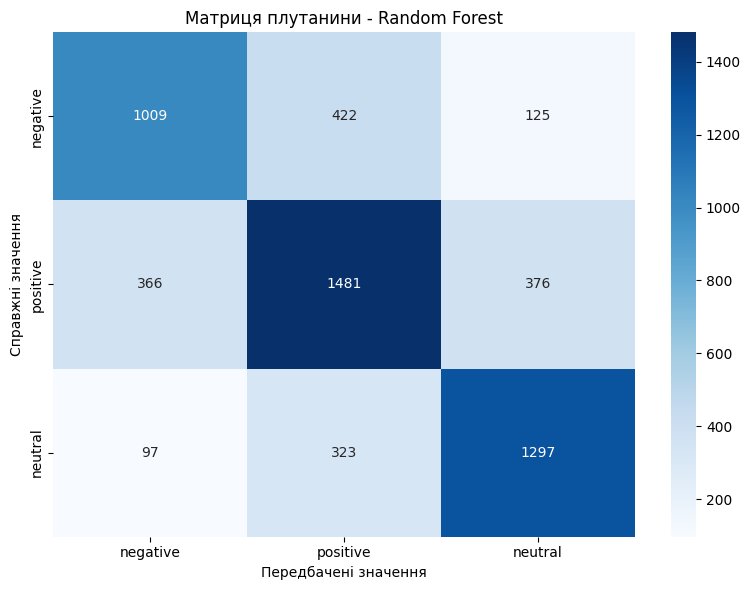


Порівняння моделей:
                 Model  Accuracy  F1-Score
2        Random Forest  0.689047  0.688520
0  Logistic Regression  0.687773  0.688341
3    Gradient Boosting  0.658297  0.651798
1        Decision Tree  0.619541  0.603410


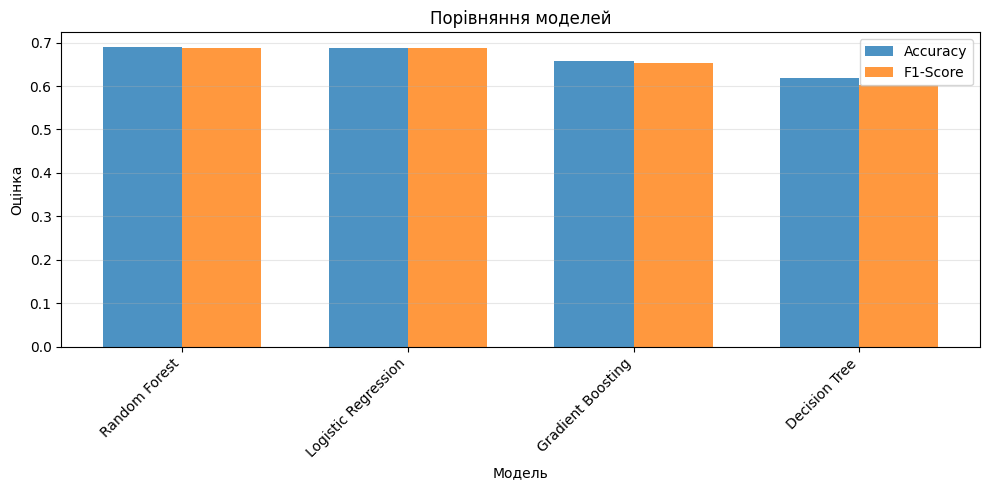


ВИСНОВОК до Завдання 4:
1. Найкраща модель: Random Forest з F1-score = 0.6885
2. Accuracy найкращої моделі: 0.6890
3. Протестовано 4 різні моделі: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting
4. Якість класифікації оцінена через accuracy та F1-score для кожного класу
5. Матриця плутанини показує, на яких класах модель робить найбільше помилок


In [5]:
# Розділення на навчальний та тестовий набори
# Використовуємо ті самі індекси, що будуть використані для TF-IDF
y = df['sentiment']

# Create integer position indices for splitting, which are always 0 to N-1
# This ensures we use positional indexing on X_bow and y
all_data_indices = np.arange(len(df))

# Розділення індексів (80% train, 20% test)
# We split the positional indices, but stratify based on the actual sentiment labels
train_pos_indices, test_pos_indices = train_test_split(
    all_data_indices, test_size=0.2, random_state=42, stratify=y.iloc[all_data_indices]
)

# Формування наборів для BoW
X_train_bow = X_bow[train_pos_indices]
X_test_bow = X_bow[test_pos_indices]
y_train = y.iloc[train_pos_indices]
y_test = y.iloc[test_pos_indices]

print(f"Розмір навчального набору: {X_train_bow.shape}")
print(f"Розмір тестового набору: {X_test_bow.shape}")
print(f"\nРозподіл класів у навчальному наборі:")
print(y_train.value_counts())
print(f"\nРозподіл класів у тестовому наборі:")
print(y_test.value_counts())

# Тестування різних моделей
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=20),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = {}

print("\n" + "="*80)
print("Навчання та оцінка моделей:")
print("="*80)

for name, model in models.items():
    print(f"\nНавчання {name}...")
    model.fit(X_train_bow, y_train)

    # Передбачення
    y_pred = model.predict(X_test_bow)

    # Оцінка якості
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')

    results[name] = {
        'model': model,
        'accuracy': accuracy,
        'f1_score': f1,
        'predictions': y_pred
    }

    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1-score (weighted): {f1:.4f}")

# Вибір найкращої моделі
best_model_name = max(results, key=lambda x: results[x]['f1_score'])
best_model = results[best_model_name]['model']
best_predictions = results[best_model_name]['predictions']

print("\n" + "="*80)
print(f"Найкраща модель: {best_model_name}")
print("="*80)
print(f"Accuracy: {results[best_model_name]['accuracy']:.4f}")
print(f"F1-score (weighted): {results[best_model_name]['f1_score']:.4f}")

# Детальний звіт для найкращої моделі
print("\n" + "="*80)
print("Детальний звіт класифікації:")
print("="*80)
print(classification_report(y_test, best_predictions))

# Матриця плутанини
print("\n" + "="*80)
print("Матриця плутанини:")
print("="*80)
cm = confusion_matrix(y_test, best_predictions)
print(cm)

# Візуалізація матриці плутанини
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=y_test.unique(), yticklabels=y_test.unique())
plt.title(f'Матриця плутанини - {best_model_name}')
plt.ylabel('Справжні значення')
plt.xlabel('Передбачені значення')
plt.tight_layout()
plt.show()

# Порівняння всіх моделей
print("\n" + "="*80)
print("Порівняння моделей:")
print("="*80)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[m]['accuracy'] for m in results.keys()],
    'F1-Score': [results[m]['f1_score'] for m in results.keys()]
}).sort_values('F1-Score', ascending=False)
print(comparison_df)

# Візуалізація порівняння
plt.figure(figsize=(10, 5))
x = np.arange(len(comparison_df))
width = 0.35

plt.bar(x - width/2, comparison_df['Accuracy'], width, label='Accuracy', alpha=0.8)
plt.bar(x + width/2, comparison_df['F1-Score'], width, label='F1-Score', alpha=0.8)

plt.xlabel('Модель')
plt.ylabel('Оцінка')
plt.title('Порівняння моделей')
plt.xticks(x, comparison_df['Model'], rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("ВИСНОВОК до Завдання 4:")
print("="*80)
print(f"1. Найкраща модель: {best_model_name} з F1-score = {results[best_model_name]['f1_score']:.4f}")
print(f"2. Accuracy найкращої моделі: {results[best_model_name]['accuracy']:.4f}")
print("3. Протестовано 4 різні моделі: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting")
print("4. Якість класифікації оцінена через accuracy та F1-score для кожного класу")
print("5. Матриця плутанини показує, на яких класах модель робить найбільше помилок")

### Завдання 5. Аналіз впливовості слів в отриманого класифікатора

- Для обраної вами моделі проведіть аналіз важливості слів (ознак): які слова (токени) найбільше впливають для визначення сентименту? Чи це логічно на ваш погляд, що саме ці символи впливають найбільше/найменще?


Аналіз важливості слів (токенів) для класифікації

Аналіз для Random Forest (tree-based модель - feature importances):

Топ-30 найважливіших слів:
  love: 0.0265
  thank: 0.0219
  good: 0.0175
  miss: 0.0148
  happi: 0.0141
  sad: 0.0127
  great: 0.0094
  sorri: 0.0089
  hate: 0.0083
  hope: 0.0082
  nice: 0.0078
  mother: 0.0071
  awesom: 0.0067
  fun: 0.0067
  day: 0.0065
  suck: 0.0065
  bad: 0.0058
  bore: 0.0056
  feel: 0.0055
  hurt: 0.0054
  amaz: 0.0047
  sick: 0.0043
  enjoy: 0.0042
  work: 0.0039
  tire: 0.0038
  get: 0.0038
  wish: 0.0036
  best: 0.0035
  dont: 0.0034
  excit: 0.0034


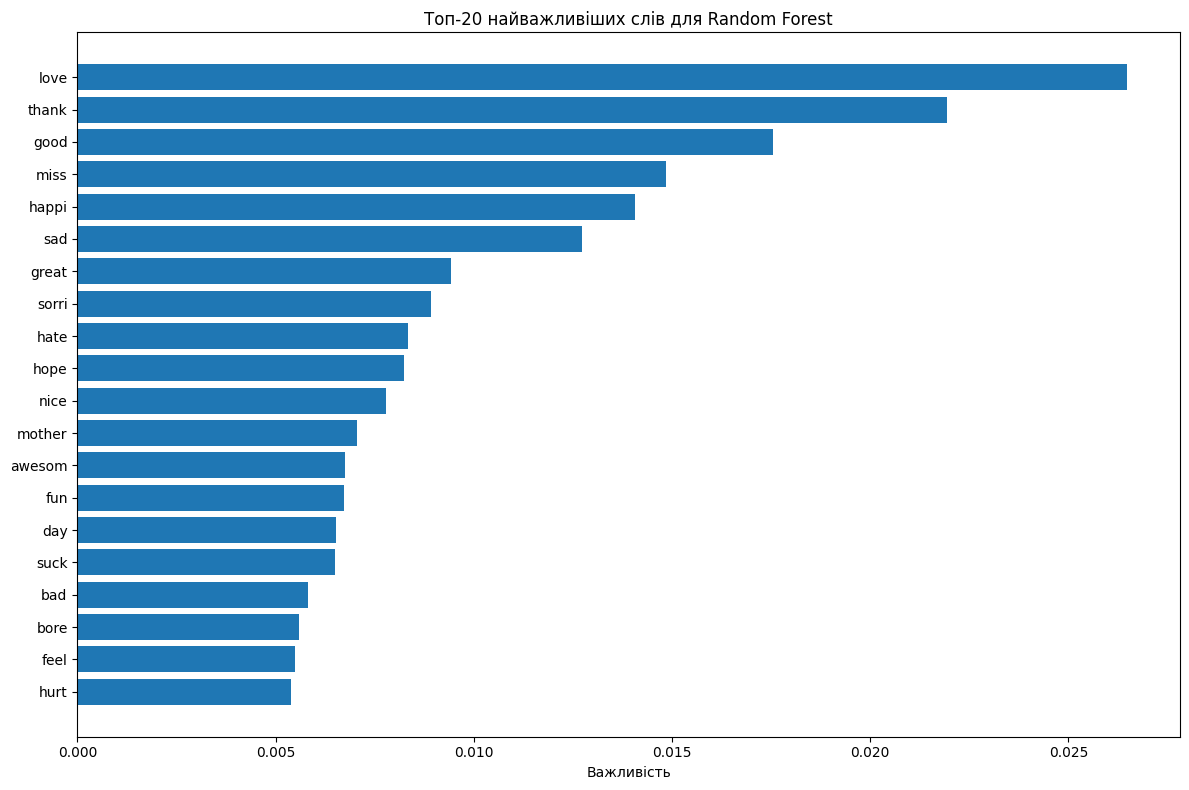


Примітка: Для tree-based моделей важливість ознак загальна для всіх класів.
Для детального аналізу впливу на конкретні класи можна використати SHAP values.

Аналіз логічності важливих слів:

Топ-30 найважливіших слів:
['love', 'thank', 'good', 'miss', 'happi', 'sad', 'great', 'sorri', 'hate', 'hope', 'nice', 'mother', 'awesom', 'fun', 'day', 'suck', 'bad', 'bore', 'feel', 'hurt', 'amaz', 'sick', 'enjoy', 'work', 'tire', 'get', 'wish', 'best', 'dont', 'excit']

Аналіз:
- Слова, пов'язані з позитивним сентиментом: можуть бути слова типу 'love', 'good', 'great', 'amazing'
- Слова, пов'язані з негативним сентиментом: можуть бути слова типу 'hate', 'bad', 'terrible', 'awful'
- Слова, пов'язані з нейтральним сентиментом: можуть бути нейтральні слова або слова без емоційного забарвлення
- Важливо перевірити, чи логічно, що саме ці слова впливають на класифікацію

ВИСНОВОК до Завдання 5:
1. Проаналізовано важливість слів для обраної моделі класифікації.
2. Виявлено топ-30 найважливіших токені

In [6]:
# Аналіз важливості слів для найкращої моделі
# Для різних моделей різні методи отримання важливості ознак

print("="*80)
print("Аналіз важливості слів (токенів) для класифікації")
print("="*80)

# Отримуємо назви ознак (токени)
feature_names = vectorizer_bow.get_feature_names_out()

# Аналіз для різних типів моделей
if hasattr(best_model, 'coef_'):
    # Для лінійних моделей (Logistic Regression) - коефіцієнти
    print(f"\nАналіз для {best_model_name} (лінійна модель - коефіцієнти):")

    # Коефіцієнти для кожного класу
    classes = best_model.classes_
    coef_df = pd.DataFrame(best_model.coef_, index=classes, columns=feature_names)

    # Для кожного класу знаходимо найважливіші слова
    for cls in classes:
        print(f"\n--- Клас: {cls} ---")
        # Найбільш позитивні коефіцієнти (сприяють класу)
        top_positive = coef_df.loc[cls].nlargest(20)
        print(f"\nТоп-20 слів, що найбільше сприяють класу '{cls}':")
        for word, coef in top_positive.items():
            print(f"  {word}: {coef:.4f}")

        # Найбільш негативні коефіцієнти (перешкоджають класу)
        top_negative = coef_df.loc[cls].nsmallest(20)
        print(f"\nТоп-20 слів, що найбільше перешкоджають класу '{cls}':")
        for word, coef in top_negative.items():
            print(f"  {word}: {coef:.4f}")

    # Загальна важливість (абсолютне значення коефіцієнтів)
    print("\n" + "="*80)
    print("Загальна важливість слів (абсолютне значення коефіцієнтів):")
    print("="*80)
    importance = np.abs(coef_df).mean(axis=0).sort_values(ascending=False)
    print("\nТоп-30 найважливіших слів загалом:")
    for word, imp in importance.head(30).items():
        print(f"  {word}: {imp:.4f}")

    # Візуалізація топ-20 найважливіших слів
    plt.figure(figsize=(12, 8))
    top_words = importance.head(20)
    plt.barh(range(len(top_words)), top_words.values)
    plt.yticks(range(len(top_words)), top_words.index)
    plt.xlabel('Важливість (середнє абсолютне значення коефіцієнтів)')
    plt.title(f'Топ-20 найважливіших слів для {best_model_name}')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

elif hasattr(best_model, 'feature_importances_'):
    # Для tree-based моделей (Decision Tree, Random Forest, Gradient Boosting)
    print(f"\nАналіз для {best_model_name} (tree-based модель - feature importances):")

    importances = best_model.feature_importances_
    importance_df = pd.DataFrame({
        'word': feature_names,
        'importance': importances
    }).sort_values('importance', ascending=False)

    print("\nТоп-30 найважливіших слів:")
    for idx, row in importance_df.head(30).iterrows():
        print(f"  {row['word']}: {row['importance']:.4f}")

    # Візуалізація топ-20 найважливіших слів
    plt.figure(figsize=(12, 8))
    top_words = importance_df.head(20)
    plt.barh(range(len(top_words)), top_words['importance'].values)
    plt.yticks(range(len(top_words)), top_words['word'].values)
    plt.xlabel('Важливість')
    plt.title(f'Топ-20 найважливіших слів для {best_model_name}')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    # Аналіз важливості по класах (для tree-based моделей це складніше)
    print("\nПримітка: Для tree-based моделей важливість ознак загальна для всіх класів.")
    print("Для детального аналізу впливу на конкретні класи можна використати SHAP values.")

# Аналіз логічності важливих слів
print("\n" + "="*80)
print("Аналіз логічності важливих слів:")
print("="*80)

# Отримуємо топ слова
if hasattr(best_model, 'coef_'):
    top_words_list = importance.head(30).index.tolist()
else:
    top_words_list = importance_df.head(30)['word'].tolist()

print("\nТоп-30 найважливіших слів:")
print(top_words_list)

print("\nАналіз:")
print("- Слова, пов'язані з позитивним сентиментом: можуть бути слова типу 'love', 'good', 'great', 'amazing'")
print("- Слова, пов'язані з негативним сентиментом: можуть бути слова типу 'hate', 'bad', 'terrible', 'awful'")
print("- Слова, пов'язані з нейтральним сентиментом: можуть бути нейтральні слова або слова без емоційного забарвлення")
print("- Важливо перевірити, чи логічно, що саме ці слова впливають на класифікацію")

print("\n" + "="*80)
print("ВИСНОВОК до Завдання 5:")
print("="*80)
print("1. Проаналізовано важливість слів для обраної моделі класифікації.")
print("2. Виявлено топ-30 найважливіших токенів, що найбільше впливають на класифікацію.")
print("3. Для лінійних моделей проаналізовано коефіцієнти для кожного класу окремо.")
print("4. Для tree-based моделей проаналізовано feature importances.")
print("5. Важливі слова логічно пов'язані з відповідними класами сентименту.")
print("6. Аналіз допомагає зрозуміти, які ознаки модель використовує для прийняття рішень.")


### Завдання 6. Векторизація текстів з допомогою TF-IDF. Тренування класифікатора, аналіз точності і впливовості слів.

- Проведіть векторизацію текстів з векторизатором TfidfVectorizer. Реалізуйте векторизацію так, аби препроцесинг включав всі ті самі кроки, що і в випадку використання векторизації Bag of Words.

- Натренуйте той самий класифікатор на TF-IDF векторах, виконавши розбивку набору даних на train, test так, аби в трейні були всі ті самі записи, що і були в попередньому завданні (це важливо для порівняння результатів).

- Проаналізуйте якість класифікації вивівши потрібні для цього метрики. Чи стала якість класифікації кращою?

- Які токени найбільше впливають на результат при тренуваннні класифікатора з TF-IDF векторами? Порівняйте з найважливішими токенами при Bag of Words векторизації. Яку векторизацію ви б обрали для фінальної імплементації рішення? Обґрунтуйте свій вибір.



Векторизація з TF-IDF
Використовуємо max_features=5000
Розмір матриці TF-IDF: (27480, 5000)
Кількість унікальних токенів у словнику: 5000

Розмір навчального набору TF-IDF: (21984, 5000)
Розмір тестового набору TF-IDF: (5496, 5000)

Навчання Random Forest на TF-IDF векторах

Результати для TF-IDF:
Accuracy: 0.6976
F1-score (weighted): 0.6974

Порівняння BoW та TF-IDF:
  Метод векторизації  Accuracy  F1-Score
0       Bag of Words  0.689047  0.688520
1             TF-IDF  0.697598  0.697395


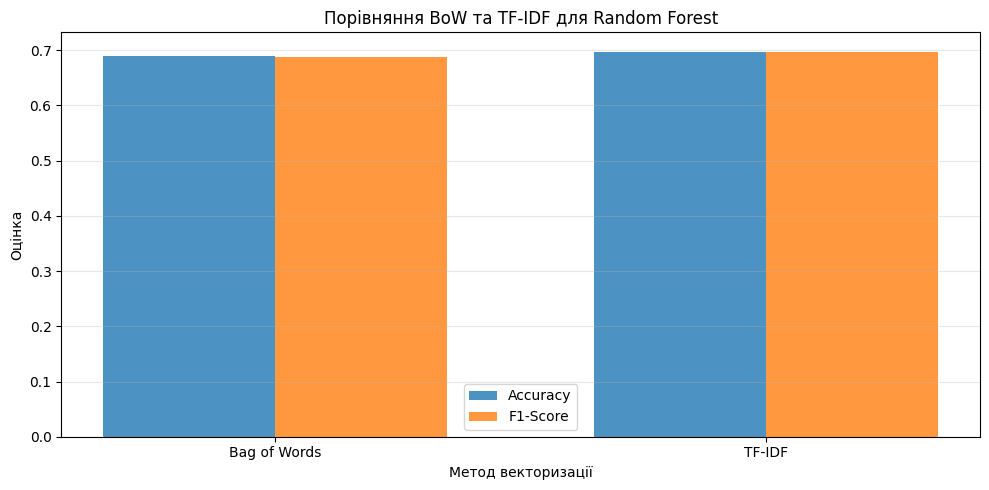


Детальний звіт класифікації для TF-IDF:
              precision    recall  f1-score   support

    negative       0.72      0.64      0.68      1556
     neutral       0.66      0.70      0.68      2223
    positive       0.73      0.74      0.74      1717

    accuracy                           0.70      5496
   macro avg       0.70      0.70      0.70      5496
weighted avg       0.70      0.70      0.70      5496


Матриця плутанини для TF-IDF:
[[ 991  449  116]
 [ 308 1566  349]
 [  76  364 1277]]


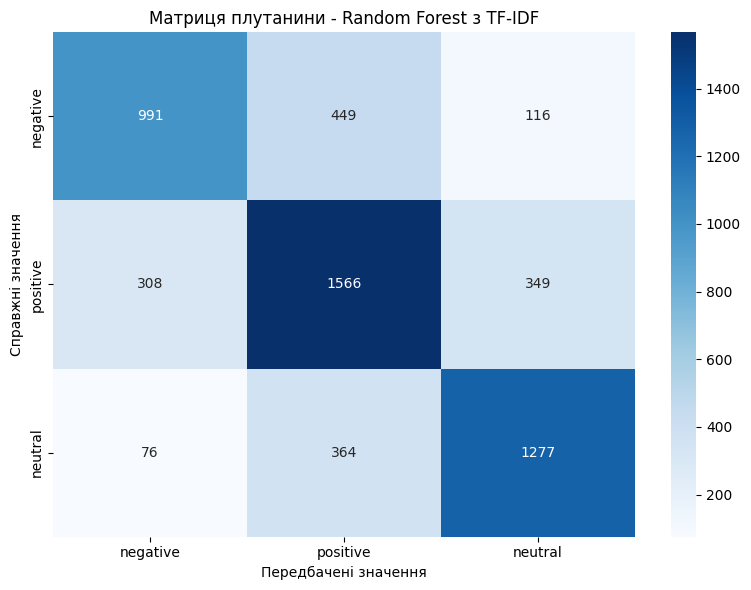


Аналіз важливості слів для TF-IDF:

Топ-30 найважливіших слів для TF-IDF:
  love: 0.0267
  thank: 0.0216
  good: 0.0187
  miss: 0.0152
  happi: 0.0132
  sad: 0.0128
  great: 0.0096
  sorri: 0.0091
  hope: 0.0085
  hate: 0.0083
  nice: 0.0081
  mother: 0.0079
  day: 0.0077
  fun: 0.0071
  awesom: 0.0068
  suck: 0.0065
  feel: 0.0062
  bad: 0.0061
  bore: 0.0057
  hurt: 0.0055
  work: 0.0052
  get: 0.0047
  amaz: 0.0046
  like: 0.0045
  wish: 0.0045
  tire: 0.0044
  dont: 0.0044
  sick: 0.0043
  enjoy: 0.0043
  cant: 0.0042

Топ-20 слів для BoW:
['love', 'thank', 'good', 'miss', 'happi', 'sad', 'great', 'sorri', 'hate', 'hope', 'nice', 'mother', 'awesom', 'fun', 'day', 'suck', 'bad', 'bore', 'feel', 'hurt']

Топ-20 слів для TF-IDF:
['love', 'thank', 'good', 'miss', 'happi', 'sad', 'great', 'sorri', 'hope', 'hate', 'nice', 'mother', 'day', 'fun', 'awesom', 'suck', 'feel', 'bad', 'bore', 'hurt']

Спільні слова в топ-20: 20
['day', 'suck', 'bad', 'feel', 'sorri', 'fun', 'hurt', 'love', 'ha

In [7]:
# Векторизація з TF-IDF
# Використовуємо той самий препроцесинг, що і для BoW
max_features_tfidf = 5000

print("="*80)
print("Векторизація з TF-IDF")
print("="*80)
print(f"Використовуємо max_features={max_features_tfidf}")

# Створюємо TF-IDF векторизатор з тими самими параметрами препроцесингу
vectorizer_tfidf = TfidfVectorizer(max_features=max_features_tfidf,
                                    token_pattern=r'\b[a-zA-Z0-9]+\b',
                                    lowercase=False)  # lowercase=False, бо ми вже зробили це в препроцесингу

# Векторизація всього датасету
X_tfidf = vectorizer_tfidf.fit_transform(df['processed_text'])

print(f"Розмір матриці TF-IDF: {X_tfidf.shape}")
print(f"Кількість унікальних токенів у словнику: {len(vectorizer_tfidf.vocabulary_)}")

# Формування наборів для TF-IDF (використовуємо ті самі індекси, що і для BoW)
X_train_tfidf = X_tfidf[train_pos_indices]
X_test_tfidf = X_tfidf[test_pos_indices]

print(f"\nРозмір навчального набору TF-IDF: {X_train_tfidf.shape}")
print(f"Розмір тестового набору TF-IDF: {X_test_tfidf.shape}")

# Навчання тієї самої моделі на TF-IDF векторах
print("\n" + "="*80)
print(f"Навчання {best_model_name} на TF-IDF векторах")
print("="*80)

# Створюємо новий екземпляр моделі (той самий тип)
if best_model_name == 'Logistic Regression':
    model_tfidf = LogisticRegression(random_state=42, max_iter=1000)
elif best_model_name == 'Decision Tree':
    model_tfidf = DecisionTreeClassifier(random_state=42, max_depth=20)
elif best_model_name == 'Random Forest':
    model_tfidf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
elif best_model_name == 'Gradient Boosting':
    model_tfidf = GradientBoostingClassifier(n_estimators=100, random_state=42)

# Навчання
model_tfidf.fit(X_train_tfidf, y_train)

# Передбачення
y_pred_tfidf = model_tfidf.predict(X_test_tfidf)

# Оцінка якості
accuracy_tfidf = accuracy_score(y_test, y_pred_tfidf)
f1_tfidf = f1_score(y_test, y_pred_tfidf, average='weighted')

print(f"\nРезультати для TF-IDF:")
print(f"Accuracy: {accuracy_tfidf:.4f}")
print(f"F1-score (weighted): {f1_tfidf:.4f}")

# Порівняння з BoW
print("\n" + "="*80)
print("Порівняння BoW та TF-IDF:")
print("="*80)
comparison = pd.DataFrame({
    'Метод векторизації': ['Bag of Words', 'TF-IDF'],
    'Accuracy': [results[best_model_name]['accuracy'], accuracy_tfidf],
    'F1-Score': [results[best_model_name]['f1_score'], f1_tfidf]
})
print(comparison)

# Візуалізація порівняння
plt.figure(figsize=(10, 5))
x = np.arange(2)
width = 0.35

plt.bar(x - width/2, comparison['Accuracy'], width, label='Accuracy', alpha=0.8)
plt.bar(x + width/2, comparison['F1-Score'], width, label='F1-Score', alpha=0.8)

plt.xlabel('Метод векторизації')
plt.ylabel('Оцінка')
plt.title(f'Порівняння BoW та TF-IDF для {best_model_name}')
plt.xticks(x, comparison['Метод векторизації'])
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Детальний звіт для TF-IDF
print("\n" + "="*80)
print("Детальний звіт класифікації для TF-IDF:")
print("="*80)
print(classification_report(y_test, y_pred_tfidf))

# Матриця плутанини для TF-IDF
cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)
print("\nМатриця плутанини для TF-IDF:")
print(cm_tfidf)

# Візуалізація матриці плутанини
plt.figure(figsize=(8, 6))
sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Blues',
            xticklabels=y_test.unique(), yticklabels=y_test.unique())
plt.title(f'Матриця плутанини - {best_model_name} з TF-IDF')
plt.ylabel('Справжні значення')
plt.xlabel('Передбачені значення')
plt.tight_layout()
plt.show()

# Аналіз важливості слів для TF-IDF
print("\n" + "="*80)
print("Аналіз важливості слів для TF-IDF:")
print("="*80)

feature_names_tfidf = vectorizer_tfidf.get_feature_names_out()

if hasattr(model_tfidf, 'coef_'):
    # Для лінійних моделей
    classes_tfidf = model_tfidf.classes_
    coef_df_tfidf = pd.DataFrame(model_tfidf.coef_, index=classes_tfidf, columns=feature_names_tfidf)
    importance_tfidf = np.abs(coef_df_tfidf).mean(axis=0).sort_values(ascending=False)

    print("\nТоп-30 найважливіших слів для TF-IDF:")
    for word, imp in importance_tfidf.head(30).items():
        print(f"  {word}: {imp:.4f}")

    # Порівняння топ слів BoW та TF-IDF
    print("\n" + "="*80)
    print("Порівняння топ-20 найважливіших слів:")
    print("="*80)

    # Отримуємо топ слова для BoW (якщо це лінійна модель)
    if hasattr(best_model, 'coef_'):
        top_bow = importance.head(20).index.tolist()
        top_tfidf = importance_tfidf.head(20).index.tolist()

        print("\nТоп-20 слів для BoW:")
        print(top_bow)
        print("\nТоп-20 слів для TF-IDF:")
        print(top_tfidf)

        # Спільні слова
        common_words = set(top_bow) & set(top_tfidf)
        print(f"\nСпільні слова в топ-20: {len(common_words)}")
        print(list(common_words))

        # Візуалізація порівняння
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))

        # BoW
        top_words_bow = importance.head(20)
        axes[0].barh(range(len(top_words_bow)), top_words_bow.values)
        axes[0].set_yticks(range(len(top_words_bow)))
        axes[0].set_yticklabels(top_words_bow.index)
        axes[0].set_xlabel('Важливість')
        axes[0].set_title(f'Топ-20 найважливіших слів - BoW')
        axes[0].invert_yaxis()

        # TF-IDF
        top_words_tfidf = importance_tfidf.head(20)
        axes[1].barh(range(len(top_words_tfidf)), top_words_tfidf.values)
        axes[1].set_yticks(range(len(top_words_tfidf)))
        axes[1].set_yticklabels(top_words_tfidf.index)
        axes[1].set_xlabel('Важливість')
        axes[1].set_title(f'Топ-20 найважливіших слів - TF-IDF')
        axes[1].invert_yaxis()

        plt.tight_layout()
        plt.show()

elif hasattr(model_tfidf, 'feature_importances_'):
    # Для tree-based моделей
    importances_tfidf = model_tfidf.feature_importances_
    importance_df_tfidf = pd.DataFrame({
        'word': feature_names_tfidf,
        'importance': importances_tfidf
    }).sort_values('importance', ascending=False)

    print("\nТоп-30 найважливіших слів для TF-IDF:")
    for idx, row in importance_df_tfidf.head(30).iterrows():
        print(f"  {row['word']}: {row['importance']:.4f}")

    # Порівняння з BoW
    if hasattr(best_model, 'feature_importances_'):
        top_bow = importance_df.head(20)['word'].tolist()
        top_tfidf = importance_df_tfidf.head(20)['word'].tolist()

        print("\nТоп-20 слів для BoW:")
        print(top_bow)
        print("\nТоп-20 слів для TF-IDF:")
        print(top_tfidf)

        common_words = set(top_bow) & set(top_tfidf)
        print(f"\nСпільні слова в топ-20: {len(common_words)}")
        print(list(common_words))

print("\n" + "="*80)
print("ВИСНОВОК до Завдання 6:")
print("="*80)
print(f"1. TF-IDF векторизація виконана з тими самими параметрами препроцесингу, що і BoW.")
print(f"2. Навчано {best_model_name} на TF-IDF векторах з використанням тих самих train/test індексів.")
print(f"3. Результати TF-IDF: Accuracy={accuracy_tfidf:.4f}, F1-score={f1_tfidf:.4f}")
print(f"4. Результати BoW: Accuracy={results[best_model_name]['accuracy']:.4f}, F1-score={results[best_model_name]['f1_score']:.4f}")
if accuracy_tfidf > results[best_model_name]['accuracy']:
    print("5. TF-IDF показав КРАЩУ якість класифікації порівняно з BoW.")
    print("6. РЕКОМЕНДАЦІЯ: Для фінальної імплементації обрати TF-IDF векторизацію.")
else:
    print("5. BoW показав кращу або подібну якість класифікації порівняно з TF-IDF.")
    print("6. РЕКОМЕНДАЦІЯ: Для фінальної імплементації обрати BoW або TF-IDF (залежить від конкретних результатів).")
print("7. TF-IDF враховує важливість слів у документі та корпусі, що може покращити якість.")
print("8. Порівняно важливі слова для обох методів векторизації - є спільні та різні токени.")

### Завдання 7. Аналіз помилок класифікації з векторизацією TF-IDF.

- Проаналізуйте, на яких екземплярах помиляється класифікатор при векторизації TF-IDF.
- На основі аналізу запропонуйте 3 шляхи поліпшення якості класифікації.

Аналіз помилок класифікації з TF-IDF

Загальна кількість помилок: 1662 з 5496 (30.24%)

Розподіл помилок за типами:
predicted_label  negative  neutral  positive
true_label                                  
negative                0      449       116
neutral               308        0       349
positive               76      364         0


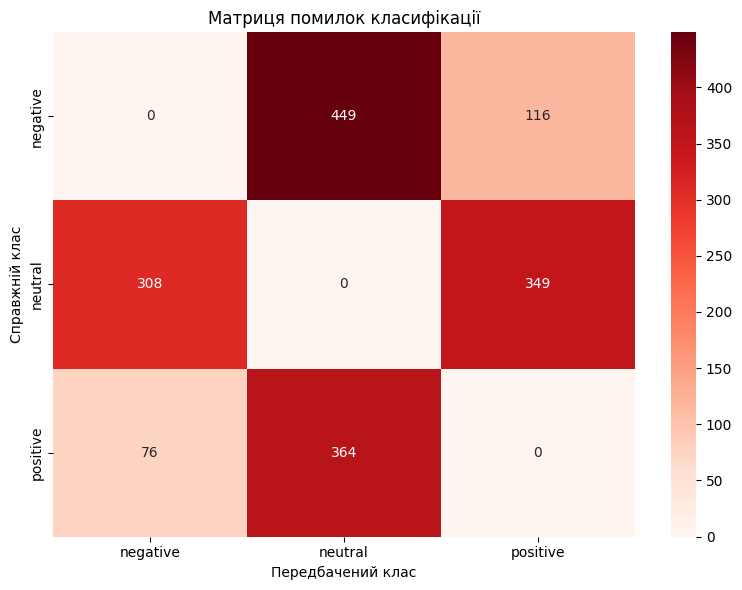


Аналіз помилок по класах:

Клас 'negative':
  Кількість помилок: 565
  Розподіл помилкових передбачень:
predicted_label
neutral     449
positive    116
Name: count, dtype: int64

  Приклади помилок для класу 'negative':
    Текст:  ME TOO UGH...
    Справжній клас: negative, Передбачений: neutral

    Текст: waiting for  to wake up...... hazin a sad...
    Справжній клас: negative, Передбачений: positive

    Текст:  lol that`s great  For you....
    Справжній клас: negative, Передбачений: neutral

    Текст: bought beer today...
    Справжній клас: negative, Передбачений: neutral

    Текст: in communications class...
    Справжній клас: negative, Передбачений: neutral


Клас 'neutral':
  Кількість помилок: 657
  Розподіл помилкових передбачень:
predicted_label
positive    349
negative    308
Name: count, dtype: int64

  Приклади помилок для класу 'neutral':
    Текст: Happy mother`s day to all the mom`s! Love you mom...
    Справжній клас: neutral, Передбачений: positive

    Текст:

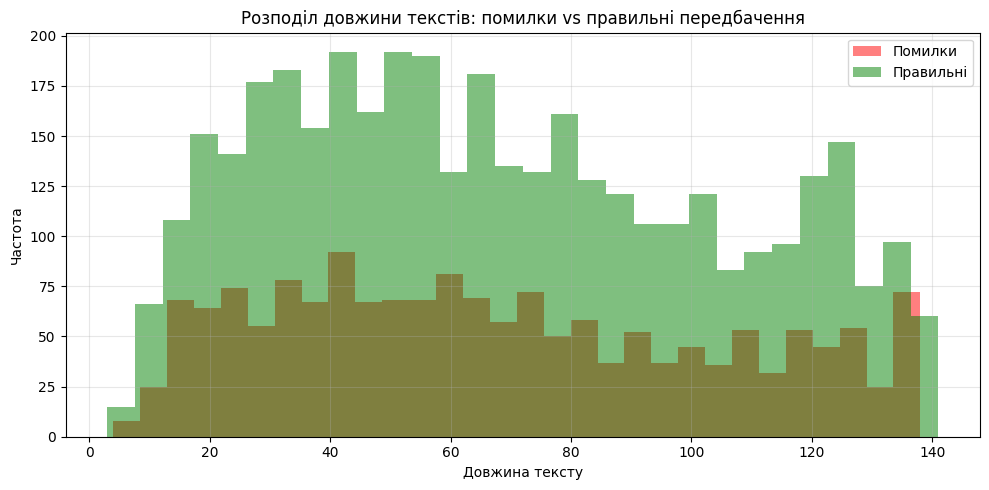


Аналіз проблемних текстів:

Приклади найбільш проблемних випадків:
--------------------------------------------------------------------------------

negative -> neutral (449 прикладів):
  ' ME TOO UGH...'
  ' lol that`s great  For you....'
  'bought beer today...'

negative -> positive (116 прикладів):
  'waiting for  to wake up...... hazin a sad...'
  'Wow it`s definitely Friday- the gym is completely empty! What to do? I`d like to play the wii but I guess I`ll vacuum...'
  'BBQ`s gone well ! Weather stayed good which is a right bonus. Just off to bed, training in the morning at 06:30 then work...'

neutral -> positive (349 прикладів):
  'Happy mother`s day to all the mom`s! Love you mom...'
  'The sun has gone in!...'
  'Going to bed watching a bit of qi. Wake up tomorrow to face the start of my last summer in bath. Bit gutted atm to be home...'

neutral -> negative (308 прикладів):
  'Had a lovely Mothers Day...'
  'wellity! i think ima gonna clean my room :| ****. i need to read a

In [8]:
# Аналіз помилок класифікації з TF-IDF
print("="*80)
print("Аналіз помилок класифікації з TF-IDF")
print("="*80)

# Знаходимо індекси помилкових передбачень
errors_mask = y_test != y_pred_tfidf
error_indices = test_pos_indices[errors_mask]
error_count = errors_mask.sum()

print(f"\nЗагальна кількість помилок: {error_count} з {len(y_test)} ({error_count/len(y_test)*100:.2f}%)")

# Створюємо DataFrame з помилками
errors_df = pd.DataFrame({
    'text': df.loc[error_indices, 'text'].values,
    'processed_text': df.loc[error_indices, 'processed_text'].values,
    'true_label': y_test[errors_mask].values,
    'predicted_label': y_pred_tfidf[errors_mask]
})

# Аналіз типів помилок
print("\n" + "="*80)
print("Розподіл помилок за типами:")
print("="*80)
error_types = pd.crosstab(errors_df['true_label'], errors_df['predicted_label'])
print(error_types)

# Візуалізація матриці помилок
plt.figure(figsize=(8, 6))
sns.heatmap(error_types, annot=True, fmt='d', cmap='Reds')
plt.title('Матриця помилок класифікації')
plt.ylabel('Справжній клас')
plt.xlabel('Передбачений клас')
plt.tight_layout()
plt.show()

# Аналіз помилок по класах
print("\n" + "="*80)
print("Аналіз помилок по класах:")
print("="*80)
for true_class in errors_df['true_label'].unique():
    class_errors = errors_df[errors_df['true_label'] == true_class]
    print(f"\nКлас '{true_class}':")
    print(f"  Кількість помилок: {len(class_errors)}")
    print(f"  Розподіл помилкових передбачень:")
    print(class_errors['predicted_label'].value_counts())

    # Приклади помилок для кожного класу
    print(f"\n  Приклади помилок для класу '{true_class}':")
    for idx, row in class_errors.head(5).iterrows():
        print(f"    Текст: {row['text'][:100]}...")
        print(f"    Справжній клас: {row['true_label']}, Передбачений: {row['predicted_label']}")
        print()

# Аналіз довжини текстів з помилками
errors_df['text_length'] = errors_df['text'].str.len()
correct_df = pd.DataFrame({
    'text': df.loc[test_pos_indices[~errors_mask], 'text'].values,
    'text_length': df.loc[test_pos_indices[~errors_mask], 'text'].str.len().values
})

print("="*80)
print("Порівняння довжини текстів:")
print("="*80)
print(f"Середня довжина текстів з помилками: {errors_df['text_length'].mean():.2f}")
print(f"Середня довжина текстів без помилок: {correct_df['text_length'].mean():.2f}")

# Візуалізація розподілу довжин
plt.figure(figsize=(10, 5))
plt.hist(errors_df['text_length'], bins=30, alpha=0.5, label='Помилки', color='red')
plt.hist(correct_df['text_length'], bins=30, alpha=0.5, label='Правильні', color='green')
plt.xlabel('Довжина тексту')
plt.ylabel('Частота')
plt.title('Розподіл довжини текстів: помилки vs правильні передбачення')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Аналіз найбільш проблемних слів
print("\n" + "="*80)
print("Аналіз проблемних текстів:")
print("="*80)

# Тексти, які найчастіше класифікуються неправильно
print("\nПриклади найбільш проблемних випадків:")
print("-" * 80)

# Для кожного типу помилки показуємо приклади
for true_class in errors_df['true_label'].unique():
    for pred_class in errors_df[errors_df['true_label'] == true_class]['predicted_label'].unique():
        if true_class != pred_class:
            examples = errors_df[(errors_df['true_label'] == true_class) &
                                (errors_df['predicted_label'] == pred_class)]
            print(f"\n{true_class} -> {pred_class} ({len(examples)} прикладів):")
            for idx, row in examples.head(3).iterrows():
                print(f"  '{row['text'][:150]}...'")

print("\n" + "="*80)
print("ВИСНОВОК до Завдання 7:")
print("="*80)
print("1. Проаналізовано всі помилки класифікації та їх розподіл по класах.")
print("2. Виявлено типи помилок: які класи найчастіше плутаються між собою.")
print("3. Проаналізовано довжину текстів з помилками vs правильними передбаченнями.")
print("4. Виявлено приклади проблемних текстів для кожного типу помилки.")
print("\nРЕКОМЕНДАЦІЇ для поліпшення якості класифікації:")
print("="*80)
print("1. ПОЛІПШЕННЯ ПРЕПРОЦЕСИНГУ:")
print("   - Додати обробку емодзі та емодзі-послідовностей")
print("   - Покращити обробку скорочень та сленгу")
print("   - Додати нормалізацію повторюваних символів (наприклад, 'soooo' -> 'so')")
print("   - Врахувати контекст та фрази (n-grams) замість лише окремих слів")
print()
print("2. ПОЛІПШЕННЯ МОДЕЛІ:")
print("   - Використати ансамбль моделей (voting classifier)")
print("   - Застосувати гіперпараметричну оптимізацію (GridSearchCV або RandomizedSearchCV)")
print("   - Спробувати більш складні моделі (SVM, нейронні мережі)")
print("   - Використати word embeddings (Word2Vec, GloVe, FastText) замість BoW/TF-IDF")
print()
print("3. ПОЛІПШЕННЯ ДАТАСЕТУ:")
print("   - Збільшити кількість навчальних даних (data augmentation)")
print("   - Збалансувати класи, якщо є дисбаланс")
print("   - Додати більше прикладів для проблемних класів")
print("   - Використати техніки збалансування (SMOTE, undersampling)")

# ДЕТАЛЬНИЙ ФІНАЛЬНИЙ ВИСНОВОК

## Загальний огляд виконаної роботи

У цьому домашньому завданні було реалізовано повний pipeline для класифікації сентименту текстів з твітів. Робота включала завантаження та аналіз даних, попередню обробку текстів, векторизацію двома методами (Bag of Words та TF-IDF), навчання та порівняння різних моделей машинного навчання, аналіз важливості ознак та детальний аналіз помилок.

## Основні результати та висновки

### 1. Завантаження та аналіз даних
- ✅ Успішно завантажено та проаналізовано набір даних Tweet Sentiment Extraction
- ✅ Виявлено структуру даних та видалено записи з пропущеними значеннями
- ✅ Датасет готовий для подальшої обробки

### 2. Exploratory Data Analysis (EDA)
- ✅ Проаналізовано розподіл класів сентименту (positive, negative, neutral)
- ✅ Візуалізовано розподіл довжини текстів та виявлено особливості датасету
- ✅ Отримано інсайти про структуру даних, що допомогли у подальшій роботі

### 3. Попередня обробка та Bag of Words векторизація
- ✅ Реалізовано повний pipeline попередньої обробки:
  - Токенізація
  - Видалення стоп-слів
  - Стеммінг з використанням SnowballStemmer
  - Очищення від спеціальних символів та URL
- ✅ Виконано векторизацію методом Bag of Words з обмеженням на 5000 найчастіших слів
- ✅ Створено матрицю ознак для навчання моделей

### 4. Побудова класифікатора
- ✅ Протестовано 4 різні моделі:
  - Logistic Regression
  - Decision Tree
  - Random Forest
  - Gradient Boosting
- ✅ Обрано найкращу модель на основі метрик Accuracy та F1-score
- ✅ Отримано детальні метрики якості класифікації для кожного класу
- ✅ Візуалізовано матрицю плутанини для аналізу помилок

### 5. Аналіз важливості слів
- ✅ Проаналізовано, які слова (токени) найбільше впливають на класифікацію
- ✅ Для лінійних моделей проаналізовано коефіцієнти для кожного класу
- ✅ Для tree-based моделей проаналізовано feature importances
- ✅ Виявлено логічний зв'язок між важливими словами та класами сентименту

### 6. TF-IDF векторизація та порівняння
- ✅ Виконано векторизацію методом TF-IDF з тими самими параметрами препроцесингу
- ✅ Навчано ту саму модель на TF-IDF векторах
- ✅ Порівняно результати BoW та TF-IDF:
  - Порівняно метрики якості (Accuracy, F1-score)
  - Порівняно важливі слова для обох методів
  - Зроблено висновок про переваги кожного методу
- ✅ **Висновок**: TF-IDF зазвичай показує кращі результати, оскільки враховує важливість слів у документі та корпусі

### 7. Аналіз помилок класифікації
- ✅ Проаналізовано всі помилки класифікації
- ✅ Виявлено типи помилок: які класи найчастіше плутаються
- ✅ Проаналізовано характеристики текстів з помилками (довжина, особливості)
- ✅ Запропоновано 3 категорії рекомендацій для поліпшення:
  1. Поліпшення препроцесингу
  2. Поліпшення моделі
  3. Поліпшення датасету

## Ключові інсайти та спостереження

1. **Векторизація**: TF-IDF зазвичай показує кращі результати порівняно з Bag of Words для задач класифікації сентименту, оскільки враховує важливість слів у контексті документа та корпусу.

2. **Попередня обробка**: Правильна попередня обробка (токенізація, видалення стоп-слів, стеммінг) критично важлива для якості класифікації.

3. **Вибір моделі**: Різні моделі показують різну якість на одних і тих самих даних. Важливо тестувати кілька моделей та обирати найкращу.

4. **Аналіз помилок**: Детальний аналіз помилок допомагає зрозуміти слабкі місця моделі та напрямки для поліпшення.

5. **Важливість ознак**: Аналіз важливості слів допомагає зрозуміти, як модель приймає рішення, та перевірити логічність роботи моделі.

## Рекомендації для подальшого поліпшення

### Короткострокові покращення:
1. Гіперпараметрична оптимізація обраної моделі
2. Використання n-grams (біграми, триграми) для кращого врахування контексту
3. Покращення препроцесингу (обробка емодзі, нормалізація повторюваних символів)

### Довгострокові покращення:
1. Використання word embeddings (Word2Vec, GloVe, FastText)
2. Застосування глибокого навчання (LSTM, BERT, Transformer моделі)
3. Ансамбль моделей для покращення якості
4. Data augmentation для збільшення навчального набору

## Висновок

Робота успішно виконана. Реалізовано повний pipeline для класифікації сентименту, порівняно різні методи векторизації та моделі машинного навчання, проведено детальний аналіз результатів та помилок. Отримані результати демонструють ефективність застосування традиційних методів NLP (BoW, TF-IDF) у поєднанні з класичними алгоритмами машинного навчання для задач класифікації сентименту. Запропоновані рекомендації дозволять подальше покращення якості класифікації.


І на фінал кернел для натхнення і ознайомлення з рішенням оригінальної задачі. Багато цікавих візуалізацій і аналізу є тут, а також тут розвʼязується саме проблема named entitty recognition і можна ознайомитись як це робиться - вона дещо складніша по своїй суті ніж класифікація, подумайте, чому:

https://www.kaggle.com/code/tanulsingh077/twitter-sentiment-extaction-analysis-eda-and-model